# Семиар 3.3. Матрицы и операции с ними. Матричные нормы. Ранг матрицы, малоранговая аппроксимация, SVD. 

## План на сегодня

- Ранг матрицы и его свойства
- Сингулярное разложение (SVD)
- Некоторые приложения сингулярного разложения

## Ранг матрицы 

**Определение.** Рангом матрицы $A$ называется максимальное число линейно независимых *столбцов* матрицы $A$.

Вы также можете использовать линейные комбинации *строк* для определения ранга, то есть формально существует два ранга: строчный и столбцовый.

**Теорема**  
Размерность пространства столбцов матрицы совпадает с размерностью пространства её строк.

[Доказательство](https://ocw.mit.edu/courses/mathematics/18-701-algebra-i-fall-2010/study-materials/MIT18_701F10_rrk_crk.pdf)

- Таким образом, ранг матрицы определяется однозначно!

## Матрица полного ранга


Матрица $A \in \mathbb{R}^{m \times n}$ называется матрицей полного ранга, если $\mathrm{rank}(A) = \min(m, n)$.

Пусть имеется матрица из $n$ столбцов.
Пусть эти столбцы сгенерированы из стандартного нормального распределения $\mathcal{N}(0, 1)$.

**Q**: Какова вероятность, что ранг этой матрицы $m < n$?

**A**: Случайная матрица является полноранговой с вероятностью 1.

## Вычисление ранга матрицы
Мы также можем попробовать вычислить ранг матрицы с помощью функции из NumPy: 

```np.linalg.matrix_rank```

In [1]:
#Computing matrix rank
import numpy as np
n = 50 
a = np.ones((n, n))
print('Rank of the matrix:', np.linalg.matrix_rank(a))
b = a + 1e-8 * np.random.randn(n, n)
print('Rank of the matrix:', np.linalg.matrix_rank(b, tol=1e-7))

Rank of the matrix: 1
Rank of the matrix: 9


### <font color='red'> Итак, малое возмущение матрицы может очень сильно повлиять на ранг! </font>

### Неустойчивость вычисления ранга матрицы

Для любой матрицы $A$ ранга $r < \min(m, n)$ существует матрица $B$ такая что её ранг равен $\min(m, n)$ и

$$
 \Vert A - B \Vert = \epsilon.
$$


**Q**: Значит ли это, что численный ранг матрицы не имеет никакого смысла? 

(Малое возмущение приводит к полному рангу!)


**A**: Нет. Нам нужно найти матрицу $B$ такую что $\|A-B\| = \epsilon$ и ранг $B$ минимален. Таким образом, мы можем вычислить ранг матрицы только с заданной точностью $\epsilon$.
Один из подходов к вычислению ранга матрицы – это сингулярное разложение матрицы (SVD).

## Сингулярное разложение

**Теорема.** Любая матрица $A\in \mathbb{C}^{n\times m}$ может быть представлена в виде произведения трёх матриц:  

$$
   A = U \Sigma V^*,
$$

где $U$ – унитарная матрица $n \times K$, $V$ – унитарная матрица $m \times K$, $K = \min(m, n)$, <br> $\Sigma$ – диагональная матрица с неотрицательными элементами на диагонали $\sigma_1 \geq  \ldots, \geq \sigma_K$. <br>
Более того, если $\text{rank}(A) = r$, тогда $\sigma_{r+1} = \dots = \sigma_K = 0$.

## Снижение размерности и малоранговая аппроксимация

- Если матрица $A$ является матрицей неполного ранга, то она представима в виде

$$ A = UV, $$

где $U \in \mathbb{R}^{n \times k}$ и $V \in \mathbb{R}^{k \times m}$

- Можно хранить только $U$ и $V$, то есть всего лишь $(n+m) k$ элементов, что может быть использовано для сжатия. Мы также можем вычислить произведение матрицы $A$ ранга $k$ на вектор $x$ гораздо быстрее:

* Умножение $y = Vx$ стоит $\mathcal{O}(mk)$ операций.
* Умножение $z = Uy$ стоит $\mathcal{O}(nk)$ операций.

Это же применимо для сложения, поэлементного умножения и других операций.
Например, для сложения:

$$
    A_1 + A_2 = U_1 V_1 + U_2 V_2 = [U_1|U_2] [V_1^\top|V_2^\top]^\top
$$

In [2]:
# A fast matrix-by-vector product demo
import numpy as np
n = 10000
r = 10
u = np.random.randn(n, r)
v = np.random.randn(n, r)
a = u.dot(v.T)
x = np.random.randn(n)
%timeit a@x
%timeit u@(v.T@x)

10.2 ms ± 206 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)
70 μs ± 154 ns per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


## Снижение размерности

- Многие данные в реальном мире лежат в пространстве высокой размерности (описываются большим количеством параметров). Например, изображения ($512\times 512$ пикселей), тексты, графы, etc.
- Однако, обрабатывать данные высокой размерности – сложная задача!

**Q**: Возможно ли уменьшить размерность данных, сохранив при этом важные отношения между объектами, например расстояние?

**[Лемма Johnson'a–Lindenstrauss'a](http://cseweb.ucsd.edu/~dasgupta/papers/jl.pdf)** 

Пусть $n\gg 1$. Дано $0 < \epsilon < 1$, $N$ точек из $\mathbb{R}^n$ и $m > \frac{8 \log N}{\epsilon^2}$ (мы хотим, чтобы $m\ll n$).

Тогда существует **линейное** отображение $f: \mathbb{R}^n \rightarrow \mathbb{R}^m$ такое что выполнено следующее неравенство:

$$(1 - \epsilon) \Vert u - v \Vert^2 \leq \Vert f(u) - f(v) \Vert^2 \leq (1 + \epsilon) \Vert u - v \Vert^2.$$


- Эта лемма утверждает, что существует линейное отображение из пространства большой размерности в пространство малой размерности такое что расстояния между точками в этих пространствах практически одинаковы.
- Утверждение не практичное из-за наличия зависимости от $\epsilon$.
- Эта лемма не даёт способа построения $f$, но гарантирует, что такое отображение существует.

## Малоранговая аппроксимация

Важная задача во многих прилоджениях – это найти малоранговое приближение для данной матрицы с точностью $\epsilon$ или рангом $r$. <br>

Примеры:
* метод главных компонент (PCA)
* факторный анализ
* линейная задача наименьших квадратов
* латентный семантический анализ

Эти задачи могут быть решены с помощью SVD.

# Теорема Eckart'a-Young'a

Наилучшая малоранговая аппроксимация может быть вычислена с помощью SVD.

**Теорема:** Пусть $r < \text{rank}(A)$, $A_r = U_r \Sigma_r V_r^*$. Тогда

$$
    \min_{\text{rank}(B)=r} \|A - B\|_2 = \|A - A_r\|_2 = \sigma_{r+1}.
$$

Похожий результат справедлив и для $\|\cdot\|_F$, но $\|A - A_r\|_F = \sqrt{\sigma_{r+1}^2 + \dots + \sigma_{\min (n,m)}^2}$.

## Основной результат о малоранговой аппроксимации

**Следствие:** вычисление наилучшей аппроксимации ранга $r$ эквивалентно использованию SVD с $\sigma_{r+1}= 0, \ldots, \sigma_K = 0$. Тогда ошибка аппроксимации равна 

$$
   \min_{A_r} \Vert A - A_r \Vert_2 = \sigma_{r+1}, \quad \min_{A_r} \Vert A - A_r \Vert_F = \sqrt{\sigma_{r+1}^2 + \dots + \sigma_{K}^2}
$$

поэтому так важно смотреть на степень убывания сингулярных чисел матрицы.

## Вычисление SVD

Алгоритмы для вычисления SVD довольно нетривиальны.

Но для вычислений мы уже можем использовать NumPy!

In [15]:
x = np.array([[1,1,1],[2,2,2],[1,2,3]])
u, s, v = np.linalg.svd(x)
print(s)

[5.28447931e+00 1.03647403e+00 4.33487171e-16]


In [14]:
np.linalg.matrix_rank(x)

np.int64(2)

In [8]:
import numpy as np
n = 100
b = np.ones((n, n)) + 1e-3*np.random.randn(n, n)
u, s, v = np.linalg.svd(b)
print(s[1]/s[0])
r = 1
u1 = u[:, :r]
s1 = s[:r]
v1 = v[:r, :]
a1 = u1.dot(np.diag(s1).dot(v1))
print(np.linalg.norm(b - a1, 2)/s[0])

0.00019996320863452068
0.00019996320863453084


In [4]:
m, n = 3, 5
A = np.random.randn(m, n)
u, s, v = np.linalg.svd(A, full_matrices=False)
print(u, "\n", s, "\n", v)
print("Check orthogonality")
print(np.linalg.norm(u.T @ u - np.eye(m)), np.linalg.norm(v @ v.T - np.eye(m)))
print("Check SVD approximation")
print(np.linalg.norm(A - u @ np.diag(s) @ v))

[[-0.08093221  0.75075729  0.65560161]
 [-0.28756605 -0.64737669  0.70583935]
 [ 0.95433524 -0.13140363  0.26828594]] 
 [3.28236443 1.82820889 0.99276454] 
 [[-0.72004139  0.18494415 -0.45837349 -0.30716749 -0.37799196]
 [-0.56972983 -0.42928414  0.34399253 -0.16102169  0.58895178]
 [ 0.02114095 -0.41964967 -0.7336244   0.46128582  0.26917995]]
Check orthogonality
1.1210090044114995e-15 8.494366212223098e-16
Check SVD approximation
3.750887759583297e-15


## Сингулярные числа случайной гауссовой матрицы 

**Q**: Как будут убывать сингулярные числа случайной матрицы?

Text(0.5, 0, 'Singular value index, $i$')

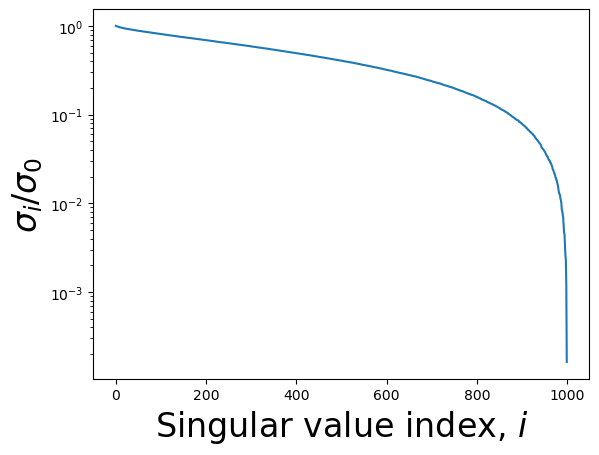

In [5]:
import numpy as np
import matplotlib.pyplot as plt
n = 1000
a = np.random.randn(n, n)
u, s, v = np.linalg.svd(a)
plt.semilogy(s/s[0])
plt.ylabel(r"$\sigma_i / \sigma_0$", fontsize=24)
plt.xlabel(r"Singular value index, $i$", fontsize=24)

## Приложения SVD

SVD имеет много разных названий, например метод главных компонент (PCA), Proper Orthogonal Decomposition, Empirical Orthogonal Functions, etc

Рассмотрим следующие прикладные задачи:

1. Разделение переменных в двумерной функции
2. Коллаборативная фильтрация
3. Сжатие полносвязных слоёв неройнной сети

## Разделение переменных для двумерной функции

**Пример 1** Мы можем использовать SVD для вычисления аппроксимации матриц, полученных из вычисления некоторой функции в точках сетки

$$a_{ij} = f(x_i, y_j),$$

где $f$ заданная функция, а $x_i, \; i = 1, \ldots, n$ и $y_j, \; j = 1, \ldots, m$ некоторые одномерные сетки.

Text(0.5, 0, 'Singular value index, $i$')

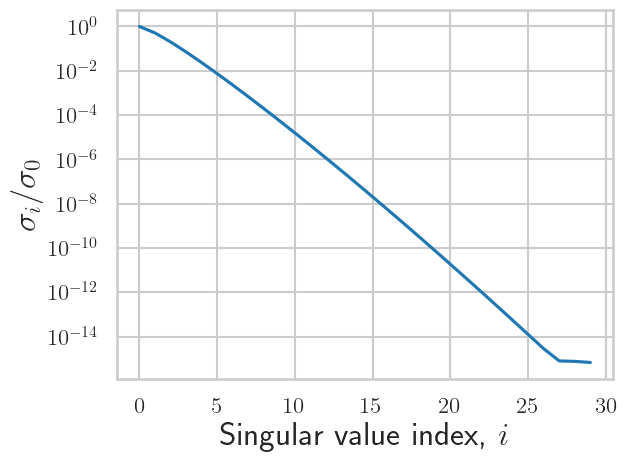

In [6]:
#%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
plt.rc("text", usetex=True)
import seaborn as sns
sns.set_style("whitegrid")
sns.set_context("talk")
# plt.xkcd()
n = 1000
a = [[1.0/(i+j+1) for i in range(n)] for j in range(n)] #Hilbert matrix 
a = np.array(a)
u, s, v = np.linalg.svd(a)
plt.semilogy(s[:30]/s[0])
plt.ylabel(r"$\sigma_i / \sigma_0$", fontsize=24)
plt.xlabel(r"Singular value index, $i$", fontsize=24)

## Коллаборативная фильтрация

- Важное приложение появилось из **рекомендательных систем**.  

- Пусть имеется матрица пользователей-продуктов: каждый пользователь ставит рейтинг некоторым продуктам.

- Тогда эта матрица имеет размер **число пользователей $\times$ число продуктов**. Задача – рекомендовать пользователям другие продукты, которые он мог бы купить.

- Схема построения рекомендаций: вычисляем SVD, и получаем рекомендации для каждого пользователя как столбец приближённой матрицы.

Подробнее на семинаре...

## Сжатие плотных матриц

Для хранения плотных матриц размера $N \times N$ обычно необходимо $N^2$ памяти. Аппроксимация ранга $r$ позволяет сократить требуемую память до $\mathcal{O}(Nr)$

3.141592653589802


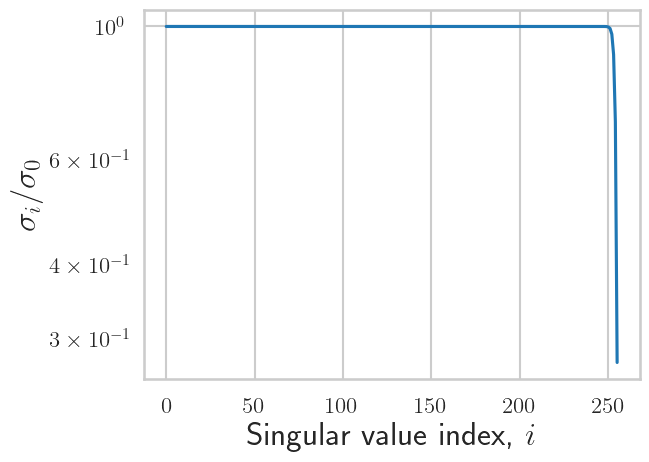

In [7]:
import numpy as np
#%matplotlib inline
import matplotlib.pyplot as plt
# plt.xkcd()
n = 256
a = [[1.0/(i - j + 0.5) for i in range(n)] for j in range(n)]
a = np.array(a)
u, s, v = np.linalg.svd(a)
plt.semilogy(s/s[0])
plt.ylabel(r"$\sigma_i / \sigma_0$", fontsize=24)
plt.grid(True)
plt.xlabel(r"Singular value index, $i$", fontsize=24)
print(s[0])

## Сжатие полносвязных слоёв нейросетей



- Одним из основных элементов современных глубоких нейронных сетей является полносвязный слой, также известный как линейный слой.
- Этот слой реализует действие линейной функции на входной вектор: $ f (x) = Wx + b $, где $ W $ - обучаемая матрица, а $ b $ - обучаемый вектор.
- $ W $ и $ b $ обновляются во время обучения сети в соответствии с некоторым методом оптимизации, например SGD, Adam и т. д.
- Однако сохранение обученных оптимальных параметров ($ W $ и $ b $) может быть недопустимым, если вы хотите перенести обученную сеть на устройство, где память ограничена.
- В качестве возможного рецепта вы можете сжать матрицы $ W_i $ из $ i $ -го линейного слоя с помощью усечённого SVD !
Что вы получите после такого приближения $ W_i $:

    - эффективное хранение
    - более быстрое вычисление
    - умеренное снижение точности решения целевой задачи - классификации изображений

## Главное в этой лекции

- Ранг матрицы
- Скелетное разложение и представление матрицы ранга $r$
- SVD и теорема Eckart'a-Young'a
- Приложения SVD